# Stellar Spectra

https://www.eso.org/sci/facilities/paranal/decommissioned/isaac/tools/lib.html

## Exercise 1
We are using for this exercise the Specrtal type B and the roman number III

**file name:** ukb3iii.dat


In [12]:
import numpy as np

data = np.loadtxt('ukxab3iii.dat')

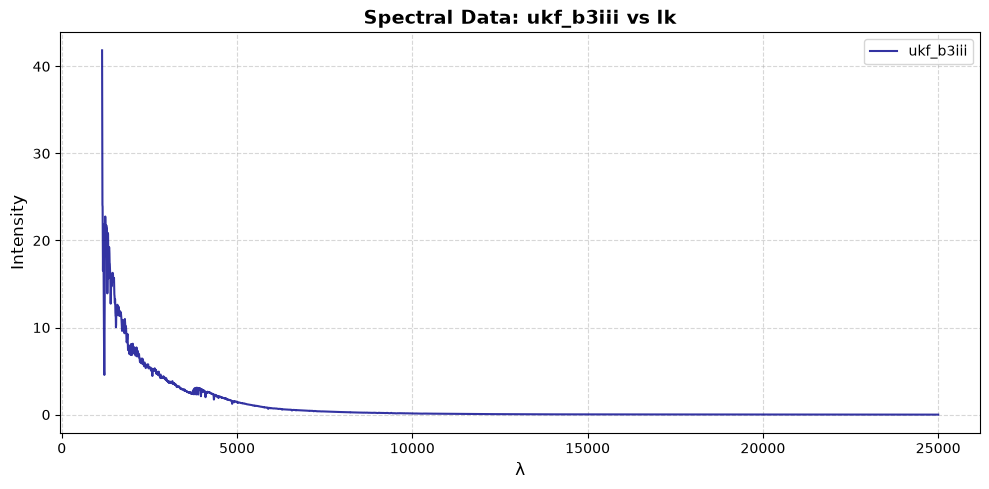

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Cargar las dos primeras columnas ignorando los encabezados con '#'
# usecols=(0, 1) selecciona la primera columna (lk) y la segunda (ukf_b3iii)
x, y = np.loadtxt("ukb3iii.dat", comments="#", usecols=(0, 1), unpack=True)

# 2. Configurar el tamaño y diseño de la gráfica
plt.figure(figsize=(10, 5))
plt.plot(x, y, linestyle="-", color="darkblue", alpha=0.8, label="ukf_b3iii")

# 3. Personalizar con los nombres reales de tus columnas
plt.title("Spectral Data: ukf_b3iii vs lk", fontsize=14, fontweight="bold")
plt.xlabel("λ", fontsize=12)
plt.ylabel("Intensity", fontsize=12)

# 4. Ajustes visuales de escala y rejilla
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right")
plt.tight_layout()

# 5. Desplegar el resultado
plt.show()


#### This we have to fit to the Black Body 

The equation of Black body is:  

$${\displaystyle B_{\lambda }(\lambda ,T)={\frac {2hc^{2}}{\lambda ^{5}}}{\frac {1}{\exp \left({\frac {hc}{\lambda k_{\mathrm {B} }T}}\right)-1}}}$$

Keep the values consistent, and also the exponential has to be dimentionless. Also, be careful with the units. 

Queremos ajustar:

$I_\lambda=A\,B_\lambda(\lambda,T)$

* T: temperatura que determina la forma de la curva.
* A: constante que ajusta su altura.
* Initial guess: una temperatura aproximada para comenzar el ajuste.

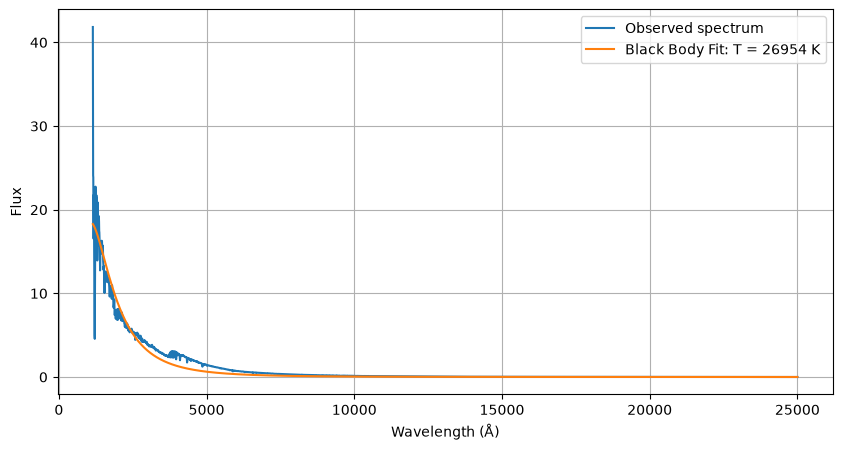

Temperature = 26954 K


In [16]:
from scipy.constants import h, c, k
from scipy.optimize import curve_fit

# Planck function
def planck(lam, T):
    lam = lam * 1e-10  # Angstroms to meters
    return (2*h*c**2 / lam**5) / np.expm1(h*c / (lam*k*T))

# Black body model
def blackbody(lam, T, A):
    return A * planck(lam, T)

# Initial guess
T0 = 18000
A0 = np.max(y) / np.max(planck(x, T0))

# Fit
params, covariance = curve_fit(
    blackbody, x, y,
    p0=[T0, A0],
    bounds=([1000, 0], [100000, np.inf]),
    maxfev=20000
)

T_fit, A_fit = params

# Plot
plt.figure(figsize=(10, 5))
plt.plot(x, y, label="Observed spectrum")
plt.plot(x, blackbody(x, T_fit, A_fit),
         label=f"Black Body Fit: T = {T_fit:.0f} K")

plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.legend()
plt.grid()
plt.show()

print(f"Temperature = {T_fit:.0f} K")

## Exercise 2

We are using for this one ukg5iii.dat

In [1]:
import numpy as np

data = np.loadtxt('ukg5iii.dat')

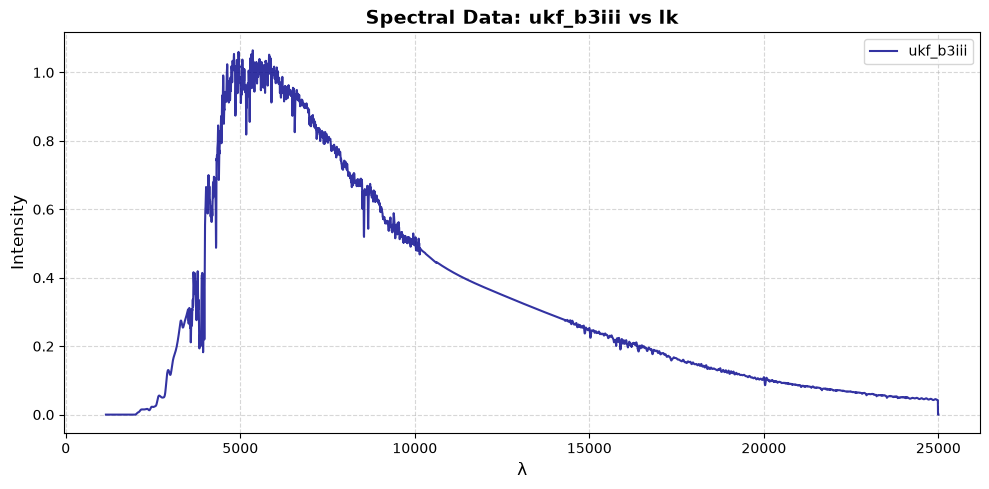

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Cargar las dos primeras columnas ignorando los encabezados con '#'
# usecols=(0, 1) selecciona la primera columna (lk) y la segunda (ukf_b3iii)
x, y = np.loadtxt("ukg5iii.dat", comments="#", usecols=(0, 1), unpack=True)

# 2. Configurar el tamaño y diseño de la gráfica
plt.figure(figsize=(10, 5))
plt.plot(x, y, linestyle="-", color="darkblue", alpha=0.8, label="ukf_b3iii")

# 3. Personalizar con los nombres reales de tus columnas
plt.title("Spectral Data: ukf_b3iii vs lk", fontsize=14, fontweight="bold")
plt.xlabel("λ", fontsize=12)
plt.ylabel("Intensity", fontsize=12)

# 4. Ajustes visuales de escala y rejilla
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right")
plt.tight_layout()

# 5. Desplegar el resultado
plt.show()


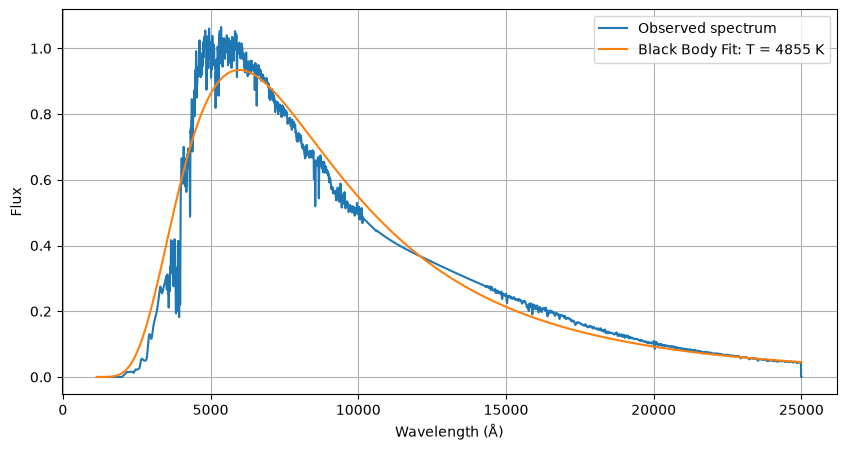

Temperature = 4855 K


In [4]:
from scipy.constants import h, c, k
from scipy.optimize import curve_fit

# Planck function
def planck(lam, T):
    lam = lam * 1e-10  # Angstroms to meters
    return (2*h*c**2 / lam**5) / np.expm1(h*c / (lam*k*T))

# Black body model
def blackbody(lam, T, A):
    return A * planck(lam, T)

# Initial guess
T0 = 18000
A0 = np.max(y) / np.max(planck(x, T0))

# Fit
params, covariance = curve_fit(
    blackbody, x, y,
    p0=[T0, A0],
    bounds=([1000, 0], [100000, np.inf]),
    maxfev=20000
)

T_fit, A_fit = params

# Plot
plt.figure(figsize=(10, 5))
plt.plot(x, y, label="Observed spectrum")
plt.plot(x, blackbody(x, T_fit, A_fit),
         label=f"Black Body Fit: T = {T_fit:.0f} K")

plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.legend()
plt.grid()
plt.show()

print(f"Temperature = {T_fit:.0f} K")

# Other codes

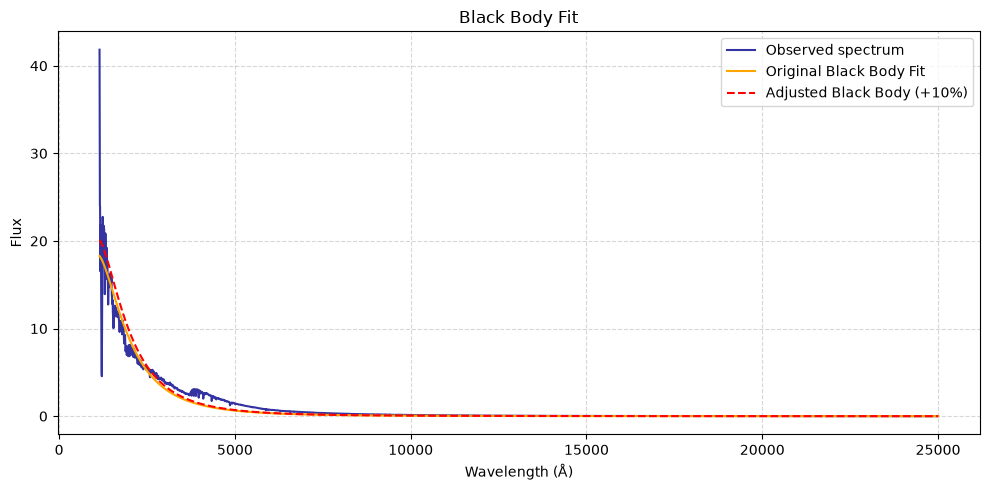

Temperature = 26954 K
Original A = 3.1709e-16
Adjusted A = 3.4880e-16


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import h, c, k
from scipy.optimize import curve_fit

# 1. Load data
x, y = np.loadtxt("ukb3iii.dat", comments="#", usecols=(0, 1), unpack=True)

# 2. Planck function
def planck(lam, T):
    lam = lam * 1e-10  # Angstroms to meters
    return (2 * h * c**2 / lam**5) / np.expm1(h * c / (lam * k * T))

# 3. Black body model
def blackbody(lam, T, A):
    return A * planck(lam, T)

# 4. Initial guess
T0 = 18000
A0 = np.max(y) / np.max(planck(x, T0))

# 5. Fit the black body
params, covariance = curve_fit(
    blackbody, x, y,
    p0=[T0, A0],
    bounds=([1000, 0], [100000, np.inf]),
    maxfev=20000
)

T_fit, A_fit = params

# 6. Adjust intensity (+10%)
A_new = A_fit * 1.1

# 7. Plot results
plt.figure(figsize=(10, 5))

plt.plot(x, y, color="darkblue", alpha=0.8,
         label="Observed spectrum")

plt.plot(x, blackbody(x, T_fit, A_fit),
         color="orange", label="Original Black Body Fit")

plt.plot(x, blackbody(x, T_fit, A_new),
         color="red", linestyle="--",
         label="Adjusted Black Body (+10%)")

plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux")
plt.title("Black Body Fit")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 8. Results
print(f"Temperature = {T_fit:.0f} K")
print(f"Original A = {A_fit:.4e}")
print(f"Adjusted A = {A_new:.4e}")